# ULTIMATE–Subaru: static structured-galaxy screen test
## tl;dr
**Executed experiment, not an ML forecast.** Spatial optical/NIR colour structure survives the assumed instrument transfer, but uniform-screen controls also show colour gradients. Population-template and SED-discrepancy assumptions change screen preferences. **A robust physical rejection of uniform foreground attenuation or unique mixed-geometry detection is not established.** Calculator-informed GLAO yields a 2–12% gain in a known-population NIR separation bound for O1; that bound is not observational recovery.

All original data/results are preserved. This notebook and its editable companion modules live in a new output subdirectory. Source snapshots, external stellar templates, parameters and numerical tables are included.

## Context & Methods
The scientific question is whether spatially non-uniform attenuation and mixed stars/dust leave detectable signatures beyond a uniform foreground screen. We separate (a) observable colour structure, (b) conditional screen-model adequacy, and (c) a privileged known-population sensitivity bound. A positive result for (a) or (c) is not proof of (b).

### Key assumptions
- Static artificial redshifting: hold **physical size, luminosity, stellar populations and dust** fixed; no intrinsic size or luminosity evolution. A z=0 galaxy is transferred observationally, not evolved into a physical high-z progenitor.
- Flat ΛCDM H0=70, Ωm=0.3. Use angular-diameter distance for sampling; Iν dims by (1+z)^−3 at corresponding rest frequency, with no duplicate Tolman factor.
- Structured DR1 maps, 100-pc native pixels. Interpolate bracketing broadband Fν in log wavelength and integrate observer-frame top hats. No extrapolation, but this is **approximate spectral synthesis**, not a validated K correction or a resolved spectrum.
- Calculator settings are provisional design inputs. Optical imaging is an explicit complementary scenario. The actual GLAO PSF and final filters/noise budget are not established.
- Fit external stellar SED mixtures and amplitude/dust nuisance parameters to **observed fluxes only**. Dust-free SKIRT maps are permitted solely in controlled truth generation.
- Priors, 5% model discrepancy, known-mean sky, separated-aperture factorization and SNR selection are assumptions. At marginal z=1 SNR, selection-conditioned inference remains unimplemented. Inspect physical null controls before interpreting evidence.

In [1]:
from pathlib import Path
import sys, os, json, subprocess, runpy
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
O=Path('/home/bahareh/ULTIMATE/analysis_results/screen_test_20261026')
sys.path.insert(0,str(O))
os.environ['MPLCONFIGDIR']='/tmp/ultimate-mpl'
os.environ['OPENBLAS_NUM_THREADS']='1'
os.environ['OMP_NUM_THREADS']='1'
print('Interpreter:',sys.executable)
# This forces genuine recomputation in the saved executed notebook. Set False only to resume already computed cases.
RECOMPUTE_MAIN=True
for file in ['implementation_plan.md','instrument_audit.md','catalogue_status.md']:
    assert (O/file).is_file()
print('Companion methods: forward_physics.py, imaging.py, instrument.py, stellar_models.py, screen_inference.py')

Interpreter: /home/bahareh/miniforge3/envs/phd/bin/python
Companion methods: forward_physics.py, imaging.py, instrument.py, stellar_models.py, screen_inference.py


### Source principles and provenance
Read source snapshots: `sources/PASSIVE_DISK_Z3_METHOD.md`, `JWST_ARTIFICIAL_REDSHIFTING_METHOD_AND_LIMITATIONS.md`, `README_JWST_artificial_redshifting.md`. Preserve their distance, wavelength, photon conversion, exact-overlap and noise-provenance principles, while using SKIRT morphology. No Galight/Sérsic morphology is substituted.

The public calculator is executed independently; the corrected model includes split reads/source Poisson/dark current and a consistent collecting area. `instrument_audit.md` records differences. The authenticated DR2 catalogue investigation retrieved metadata only and did **not** identify a release-specific DR2 endpoint. No image archive was downloaded.

In [2]:
commits={}
for name,file in [('forward repository','forward_repository_tree.json'),('calculator','calculator_tree.json'),('stellar templates','stellar_template_tree.json')]:
    commits[name]=json.loads((O/'sources'/file).read_text())['sha']
display(pd.Series(commits,name='Pinned commit'))
print('Catalogue investigation:',json.loads((O/'tng_catalogue_probe.json').read_text())[0]['status'])

forward repository    78dce5ad96038fe7a702d3e2f2b434a2c7d7e8af
calculator            2187748a40d4207519a8eff0d2a5b6701db8da0d
stellar templates     f651e94d91042a84906090a66d2a3fec75504e21
Name: Pinned commit, dtype: str

Catalogue investigation: success


### Physics and numerical gates
Analytic tests check exact pixel overlap, cosmological duality/specific intensity, the photon integral, no wavelength extrapolation, split-exposure moments and normalized hierarchical evidence. Additional uniform/varying known-family tests verify the inference can select the correct family when populations are correctly specified. That is a numerical gate, not proof of physical population completeness.

In [3]:
for test in ['test_physics.py','test_inference_controls.py']:
    result=subprocess.run([sys.executable,str(O/test)],cwd=O,capture_output=True,text=True)
    print(test, result.stdout, result.stderr)
    assert result.returncode==0
runpy.run_path(str(O/'validation_extra.py'),run_name='__main__')

test_physics.py  .....
----------------------------------------------------------------------
Ran 5 tests in 1.038s

OK



test_inference_controls.py  ..
----------------------------------------------------------------------
Ran 2 tests in 0.002s

OK



{
  "pinned_git_blobs_validated": 32,
  "distance_flux_duality": [
    {
      "z": 0.1,
      "relative_error": 2.220446049250313e-16
    },
    {
      "z": 0.3,
      "relative_error": 6.661338147750939e-16
    },
    {
      "z": 0.6,
      "relative_error": 0.0
    },
    {
      "z": 1.0,
      "relative_error": 2.220446049250313e-16
    },
    {
      "z": 3.0,
      "relative_error": 0.0
    }
  ],
  "aperture_variance_empirical_ratio": 1.031487380838423,
  "electron_conversion_max_fractional_vs_central_wavelength": 0.0014925419298723597,
  "original_pilot_sha256": "ba9ed6be682f65d5a8687ebf46c86170abe22279a3a615357fa8d6b05a46dcbd",
  "original_pilot_matches_previous_run": true,
  "source_only_shape_files_prohibited_in_fitter": true,
  "scientific_review": "Independent reviewer found no critical physics bug; false screen rejection from population/template mismatch and unconditioned marginal SNR selection prohibit a physical geometry-detection claim."
}


{'__name__': '__main__',
 '__doc__': None,
 '__package__': '',
 '__loader__': None,
 '__spec__': None,
 '__file__': '/home/bahareh/ULTIMATE/analysis_results/screen_test_20261026/validation_extra.py',
 '__cached__': None,
 '__builtins__': {'__name__': 'builtins',
  '__doc__': "Built-in functions, types, exceptions, and other objects.\n\nThis module provides direct access to all 'built-in'\nidentifiers of Python; for example, builtins.len is\nthe full name for the built-in function len().\n\nThis module is not normally accessed explicitly by most\napplications, but can be useful in modules that provide\nobjects with the same name as a built-in value, but in\nwhich the built-in of that name is also needed.",
  '__package__': '',
  '__loader__': _frozen_importlib.BuiltinImporter,
  '__spec__': ModuleSpec(name='builtins', loader=<class '_frozen_importlib.BuiltinImporter'>, origin='built-in'),
  '__build_class__': <function __build_class__>,
  '__import__': <function __import__(name, globals

## Data
Thirteen source bands spanning FUV to W1, dust-aware/dust-free, plus dust projection for five related views were streamed from the existing local archive and cropped to the same 80-kpc field. Raw FITS are not extracted/modified. The input grid is retained at 100 pc; no finer physical structure is invented. The analysis lattice covers R<18 kpc; diagnostic projection integrals use R<20 kpc.

Uniform and variable screen generators preserve the structured stellar scene and match the mixed truth's central integrated g attenuation, then remain fixed across redshift. The fitted stellar library is external and never reads these latent maps. All five orientations belong to the same galaxy.

In [4]:
if not all((O/'input_cache'/f'O{i}_structured_broadbands.npz').exists() for i in range(1,6)):
    runpy.run_path(str(O/'prepare_skirt.py'),run_name='__main__')
manifest=json.loads((O/'sources/skirt_stream_manifest.json').read_text())
assert len(manifest)==135
with np.load(O/'input_cache/O1_structured_broadbands.npz') as cache:
    display(pd.DataFrame({'source_band':cache['band'],'approximate_pivot_um':cache['wave_um']}))
    print('Structured stack:',cache['dusty'].shape,'; native pixels 100 pc')

,source_band,approximate_pivot_um
0,GALEX_FUV,0.153
1,GALEX_NUV,0.231
2,LSST_u,0.367
3,LSST_g,0.482
4,LSST_r,0.622
5,LSST_i,0.754
6,LSST_z,0.869
7,LSST_y,0.971
8,Euclid_Y,1.080
9,2MASS_J,1.235


Structured stack: (13, 800, 800) ; native pixels 100 pc


### Instrument-informed electrons and exposure splitting
Synthetic source rates integrate A Fν T(λ)/(hλ) dλ after converting surface brightness with angular pixel solid angle. Per-band exposures of 0.25/1/4 h comprise 15/60/240 independent 60-s integrations. The summed Poisson/Gaussian draw is exactly equivalent to independent exposures under the stated detector assumptions. Variance includes **N RN²**, not one read. Sky/thermal/moon/Poisson plus provisional dark current are counted once.

The source calculator's median Ks D50 is ~0.390 arcsec GLAO versus 0.588 arcsec seeing; equality with FWHM requires the primary Gaussian assumption. The optimistic 0.2-arcsec scenario and Moffat wings are tested separately. The known-sky mean baseline excludes real reduction floors/covariance. The 5% inference discrepancy is not an instrument measurement.

In [5]:
from instrument import write_instrument
write_instrument()
display(pd.read_csv(O/'instrument_parameters.csv')[['band','background_e_s_pixel','read_noise_e','dark_e_s','seeing_fwhm_arcsec','glao_fwhm_arcsec','status']])

,band,background_e_s_pixel,read_noise_e,dark_e_s,seeing_fwhm_arcsec,glao_fwhm_arcsec,status
0,g,3.528898,5.0,0.001,0.700000,0.700000,analyst optical scenario; not an ULTIMATE opti...
1,r,6.849483,5.0,0.001,0.700000,0.700000,analyst optical scenario; not an ULTIMATE opti...
2,i,11.524840,5.0,0.001,0.700000,0.700000,analyst optical scenario; not an ULTIMATE opti...
3,z,13.897499,5.0,0.001,0.700000,0.700000,analyst optical scenario; not an ULTIMATE opti...
4,Y,83.053394,16.0,0.010,0.681966,0.555782,calculator design scenario; D50 treated as Gau...
5,J,229.972447,16.0,0.010,0.657832,0.507657,calculator design scenario; D50 treated as Gau...
6,H,967.765648,16.0,0.010,0.624259,0.445599,calculator design scenario; D50 treated as Gau...
7,Ks,448.359259,16.0,0.010,0.588137,0.389551,calculator design scenario; D50 treated as Gau...


## Results
### Execute the static transfer and observational fitting
O1 runs four redshifts, three depths, two PSF modes and three truth families with three noise draws. O2–O5 repeat z=0.3 at one hour. Fits share common priors and use 0.8-arcsec matched-PSF photometry with propagated aperture errors. Separate NIR colour diagnostics retain the mode-specific common NIR PSF.

The finite external FSPS templates include baseline internal reddening. The near-clear subset has effective Av<0.15; the broad prior admits all 12 templates and their mixtures as a conservative population/SED degeneracy check. Fitted dust is therefore an **extra screen relative to the templates**, not a uniquely inferred total foreground extinction. Normalizations and template/mixture/dust alternatives are marginalized, not fixed to the intrinsic SKIRT colours.

In [6]:
import run_experiment
run_experiment.run(recompute=RECOMPUTE_MAIN)
results=pd.read_csv(O/'screen_model_results.csv')
print('Fit rows:',sum(results.status=='fit'),'Retained insufficient-aperture cases:',sum(results.status!='fit'))
display(results.groupby(['orientation','truth','population_prior']).log_B_variable_uniform.median().unstack().round(3))

O1 0.1 seeing rows 54 time 16:18:41


O1 0.1 glao rows 54 time 16:19:01


O1 0.3 seeing rows 54 time 16:19:09


O1 0.3 glao rows 54 time 16:19:18


O1 0.6 seeing rows 54 time 16:19:27


...

O5 0.3 seeing rows 18 time 16:20:31


O5 0.3 glao rows 18 time 16:20:35


Completed 575 fits


Fit rows: 574 Retained insufficient-aperture cases: 1


population_prior              broad  near_clear
orientation truth                              
O1          mixed_SKIRT      -1.746      -2.478
            uniform_control  -4.438      -3.804
            variable_control -3.799       2.766
O2          mixed_SKIRT      -7.263      -7.823
            uniform_control  -2.507      -5.381
            variable_control -6.552      -4.154
O3          mixed_SKIRT      -3.088      -7.713
            uniform_control  -5.629     -12.088
            variable_control -4.373     -11.438
O4          mixed_SKIRT      -2.045      10.021
            uniform_control  -6.657     -10.027
            variable_control -0.387       9.560
O5          mixed_SKIRT      -2.402       1.450
            uniform_control  -5.796     -11.784
            variable_control  0.021       9.766

### Robustness and diagnostics
Recompute discrepancy priors at 2/5/10%, a finer Av grid, an alternate wavelength-interpolation coordinate, and native PSF-family/optimistic-resolution sensitivity bounds. The native known-population bound is privileged and must not be called an observational dust-detection significance.

In [7]:
runpy.run_path(str(O/'run_robustness.py'),run_name='__main__')
runpy.run_path(str(O/'postprocess.py'),run_name='__main__')
runpy.run_path(str(O/'write_scientific_report.py'),run_name='__main__')
display(pd.read_csv(O/'workshop_evidence_table.csv'))

Robustness O1 0.1 complete


Robustness O1 0.3 complete


Robustness O1 0.6 complete


Robustness O1 1.0 complete


Robustness O4 0.3 complete


...

PSF robustness 0.3 complete


PSF robustness 0.6 complete


PSF robustness 1.0 complete


Saved six paired figures and summaries.
Scientific report and README saved.


,z,truth,population_prior,logB_median,n_apertures_median
0,0.1,mixed_SKIRT,broad,-22.477,69.0
1,0.1,mixed_SKIRT,near_clear,-25.441,69.0
2,0.1,uniform_control,broad,-33.095,69.0
3,0.1,uniform_control,near_clear,-28.878,69.0
4,0.3,mixed_SKIRT,broad,-4.490,13.0
5,0.3,mixed_SKIRT,near_clear,-4.937,13.0
6,0.3,uniform_control,broad,-5.955,13.0
7,0.3,uniform_control,near_clear,-13.182,13.0
8,0.6,mixed_SKIRT,broad,5.560,5.0
9,0.6,mixed_SKIRT,near_clear,9.481,5.0


### Physical null controls change the conclusion
Positive ln B favors the additional varying-screen hypothesis **under the stated priors**. Positive values for a known physical uniform screen are false physical rejections and invalidate a dust-geometry claim. Widening population freedom or the model-discrepancy budget changes the inference. Negative evidence for varying screens does not prove the real dust is uniform.

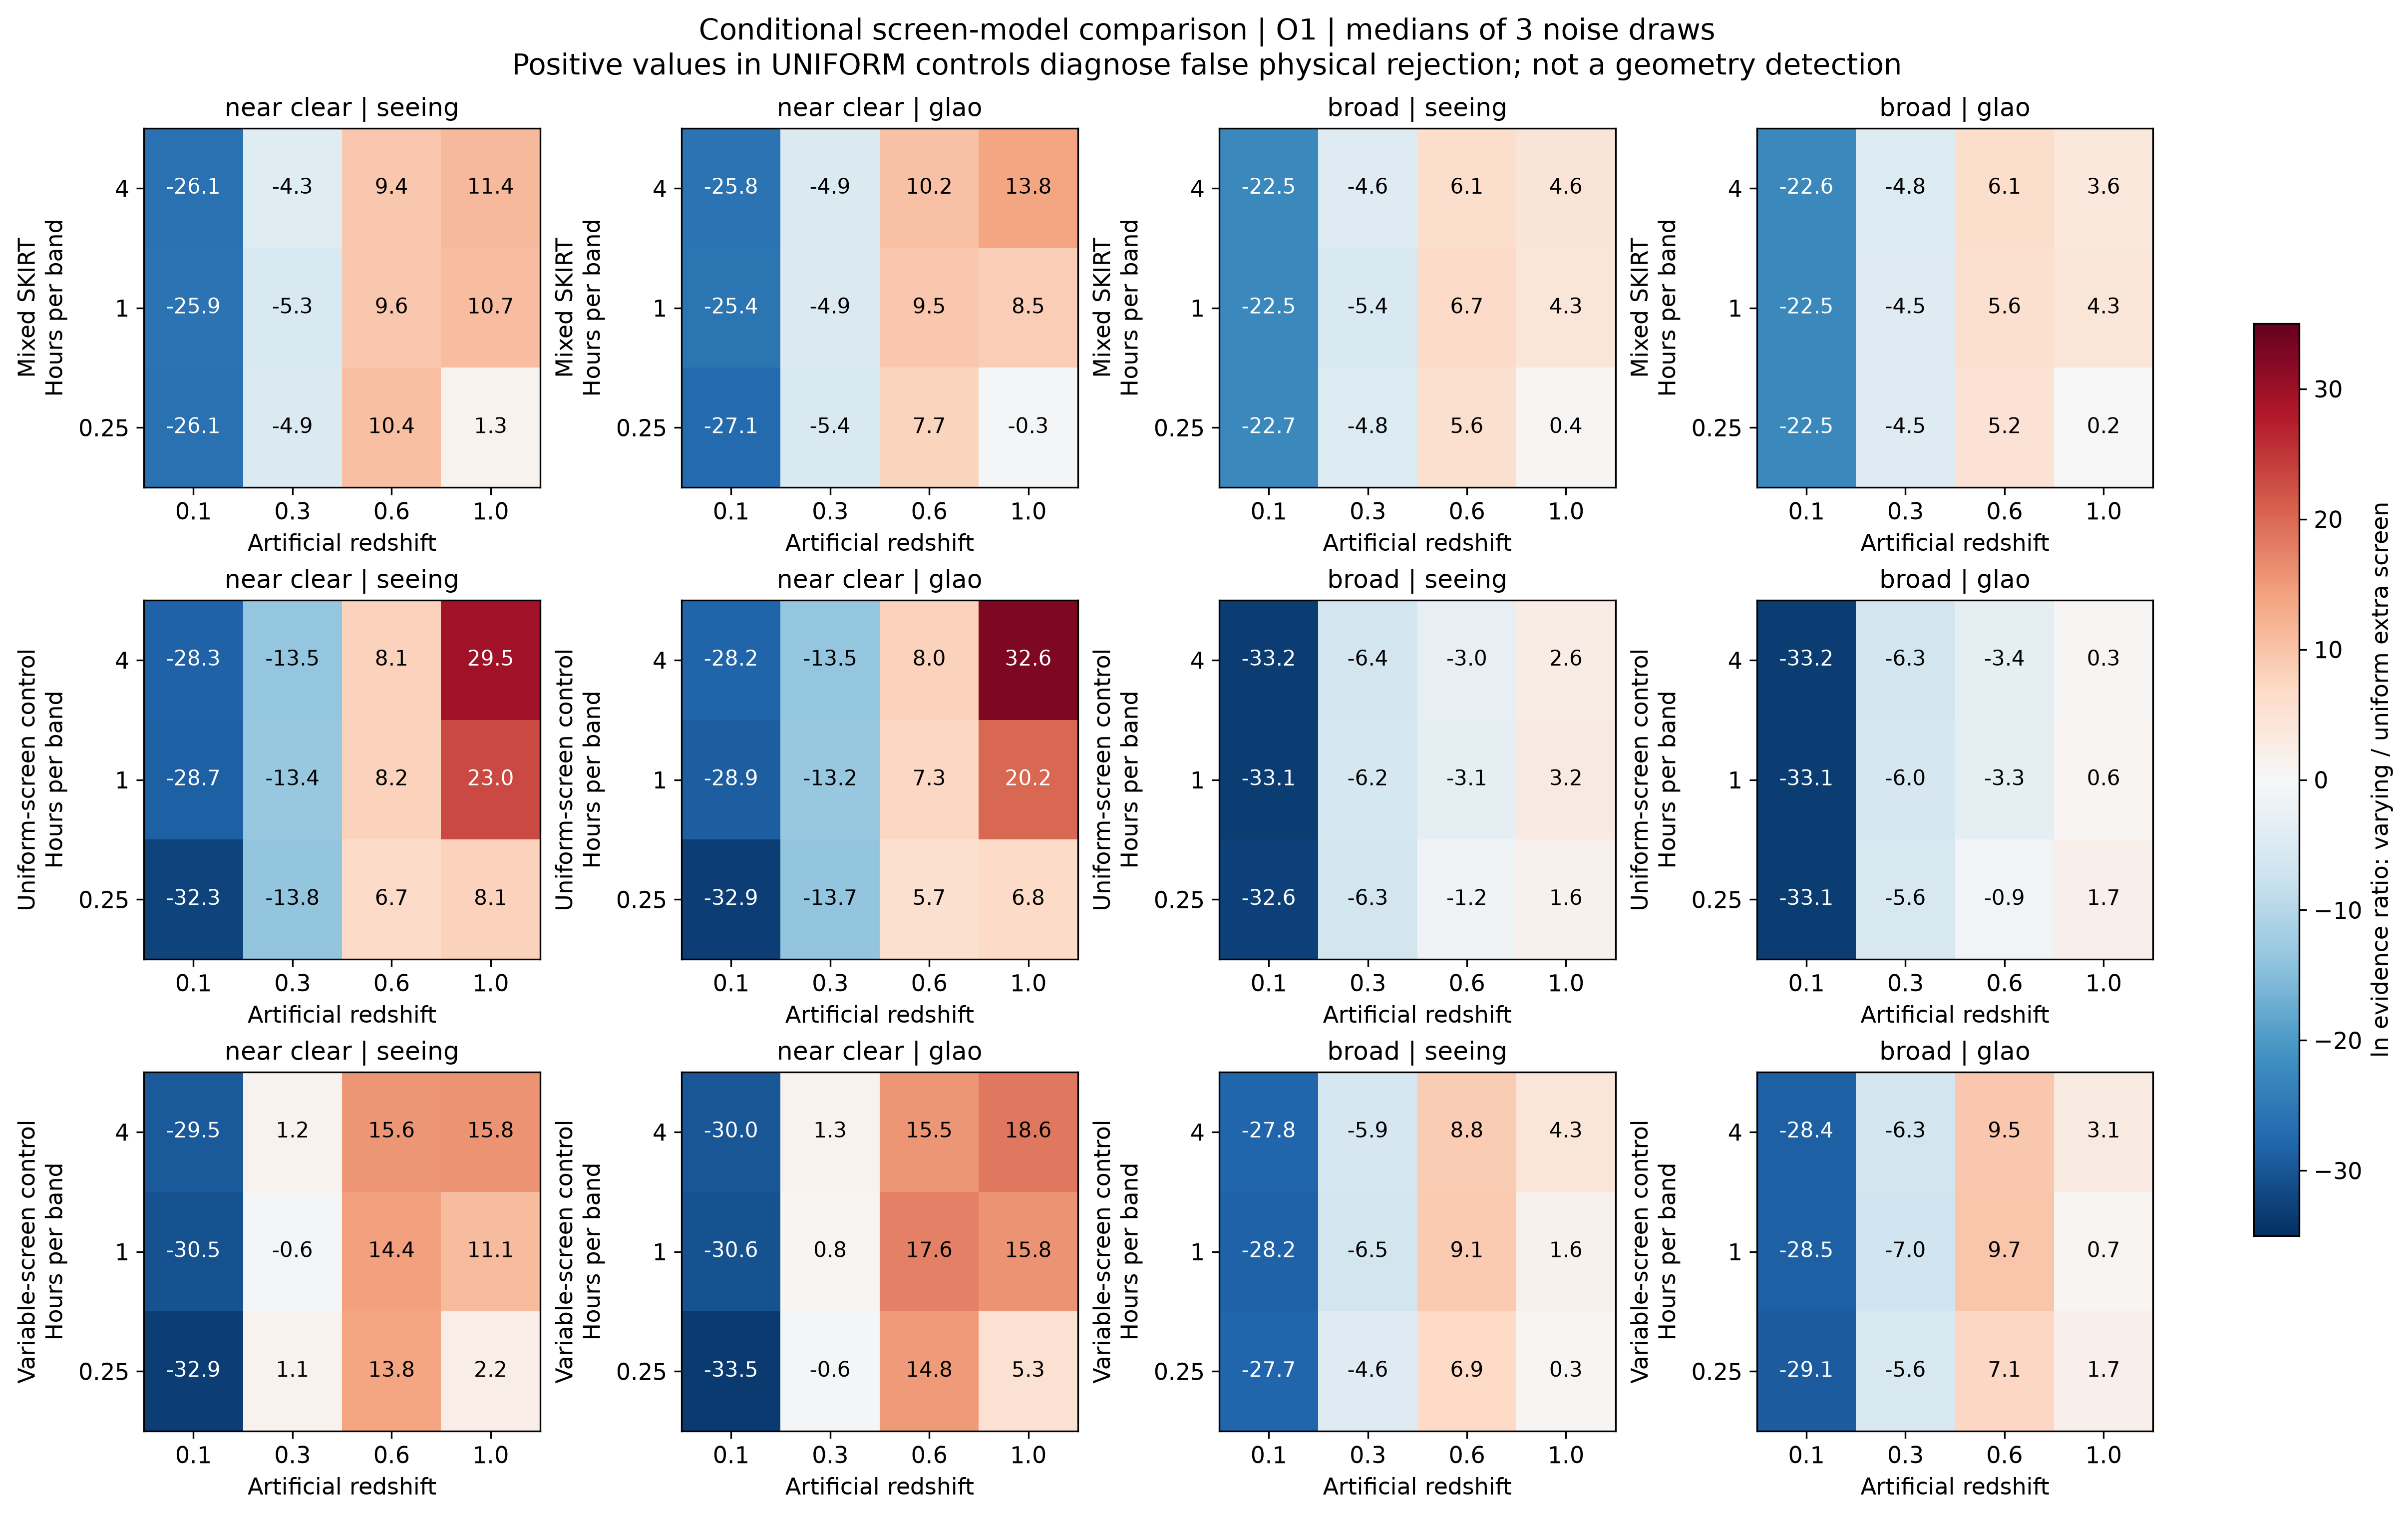

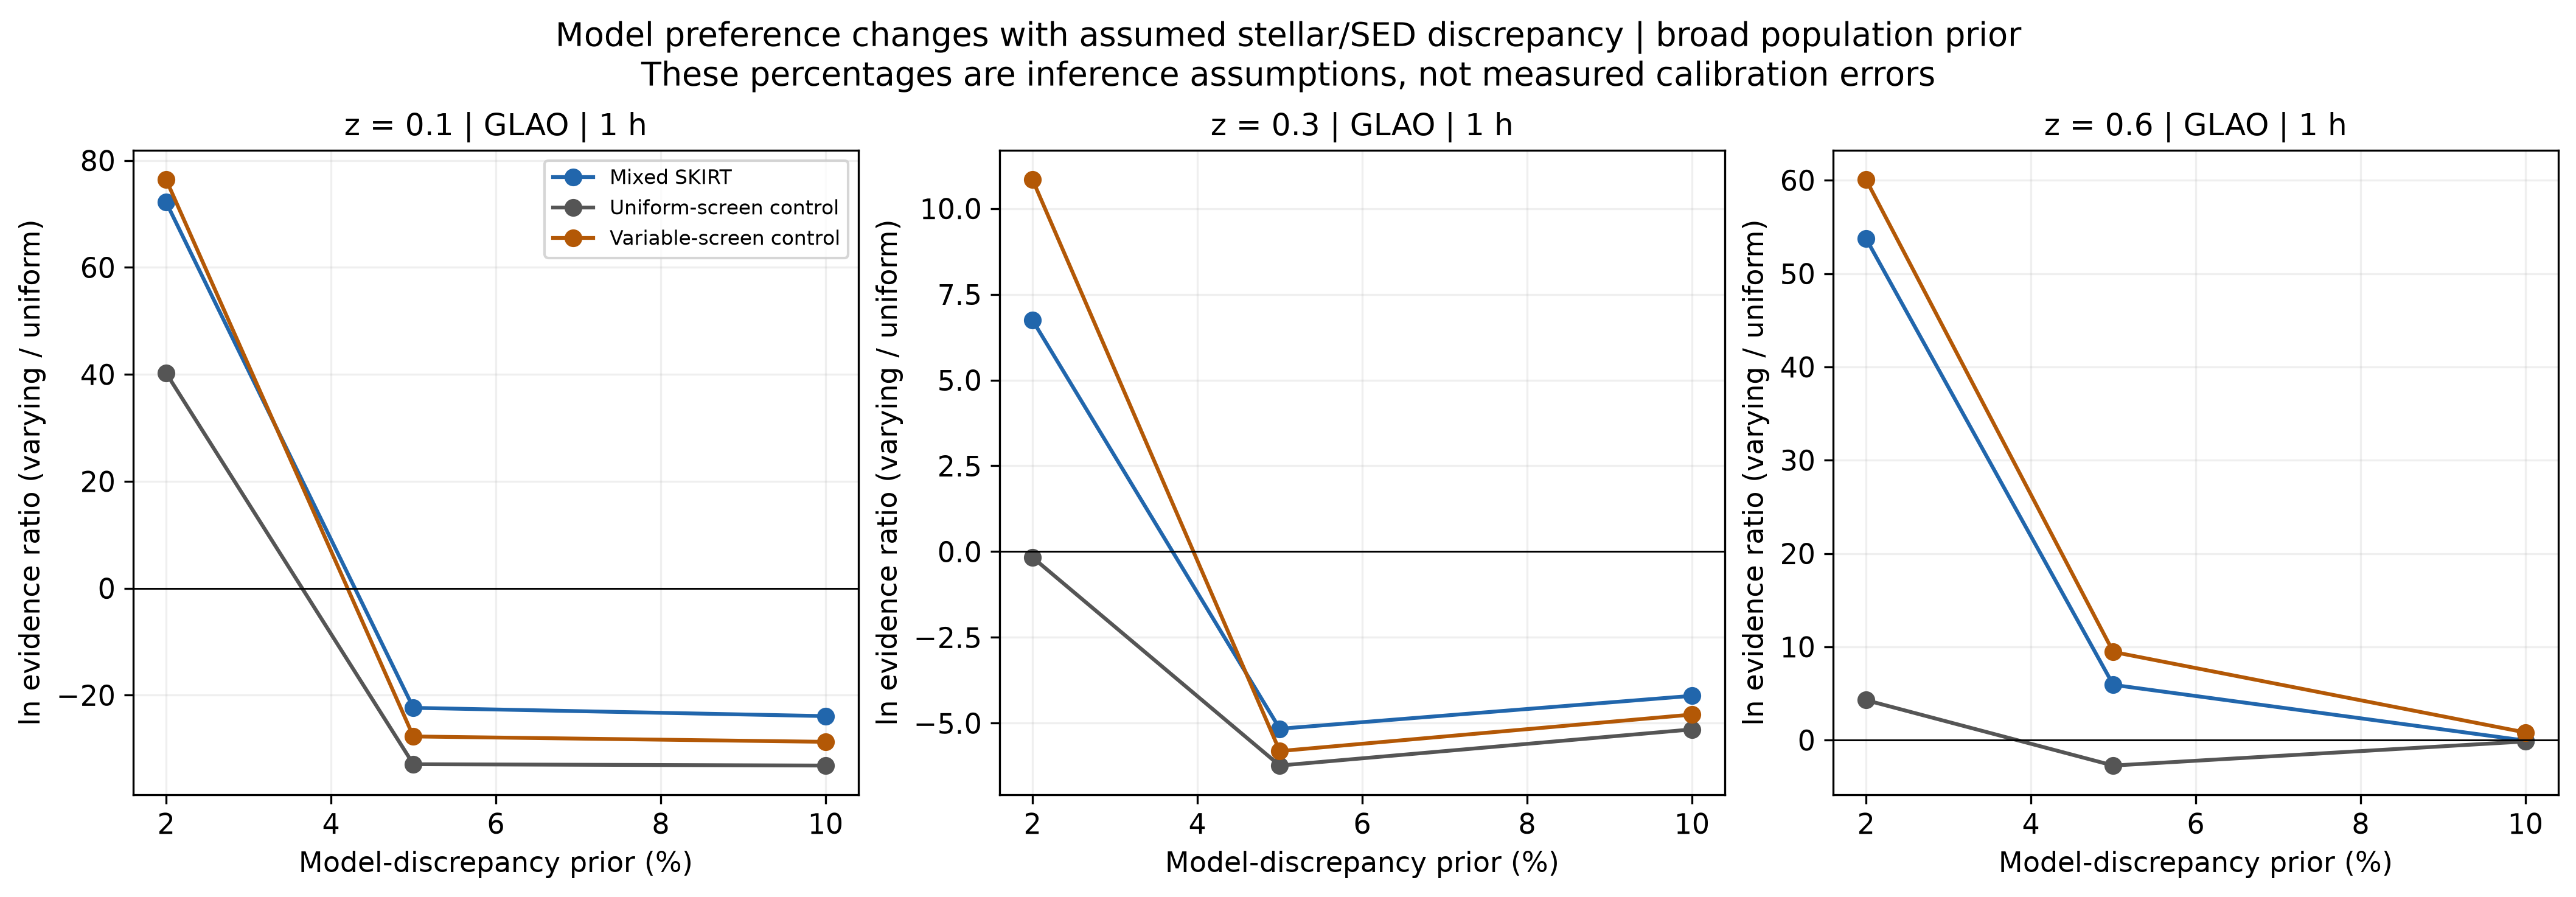

In [8]:
display(Image(filename=str(O/'figures/screen_evidence_with_null_controls.png'),width=1400))
display(Image(filename=str(O/'figures/model_discrepancy_robustness.png'),width=1200))

### Observable colours and residuals
These are noisy observable colours and posterior-mean uniform-screen colour residuals, not intrinsic attenuation or dust maps. The uniform-screen control can have large colour gradients from stellar populations alone. Residual differences between stellar priors expose modelling degeneracy.

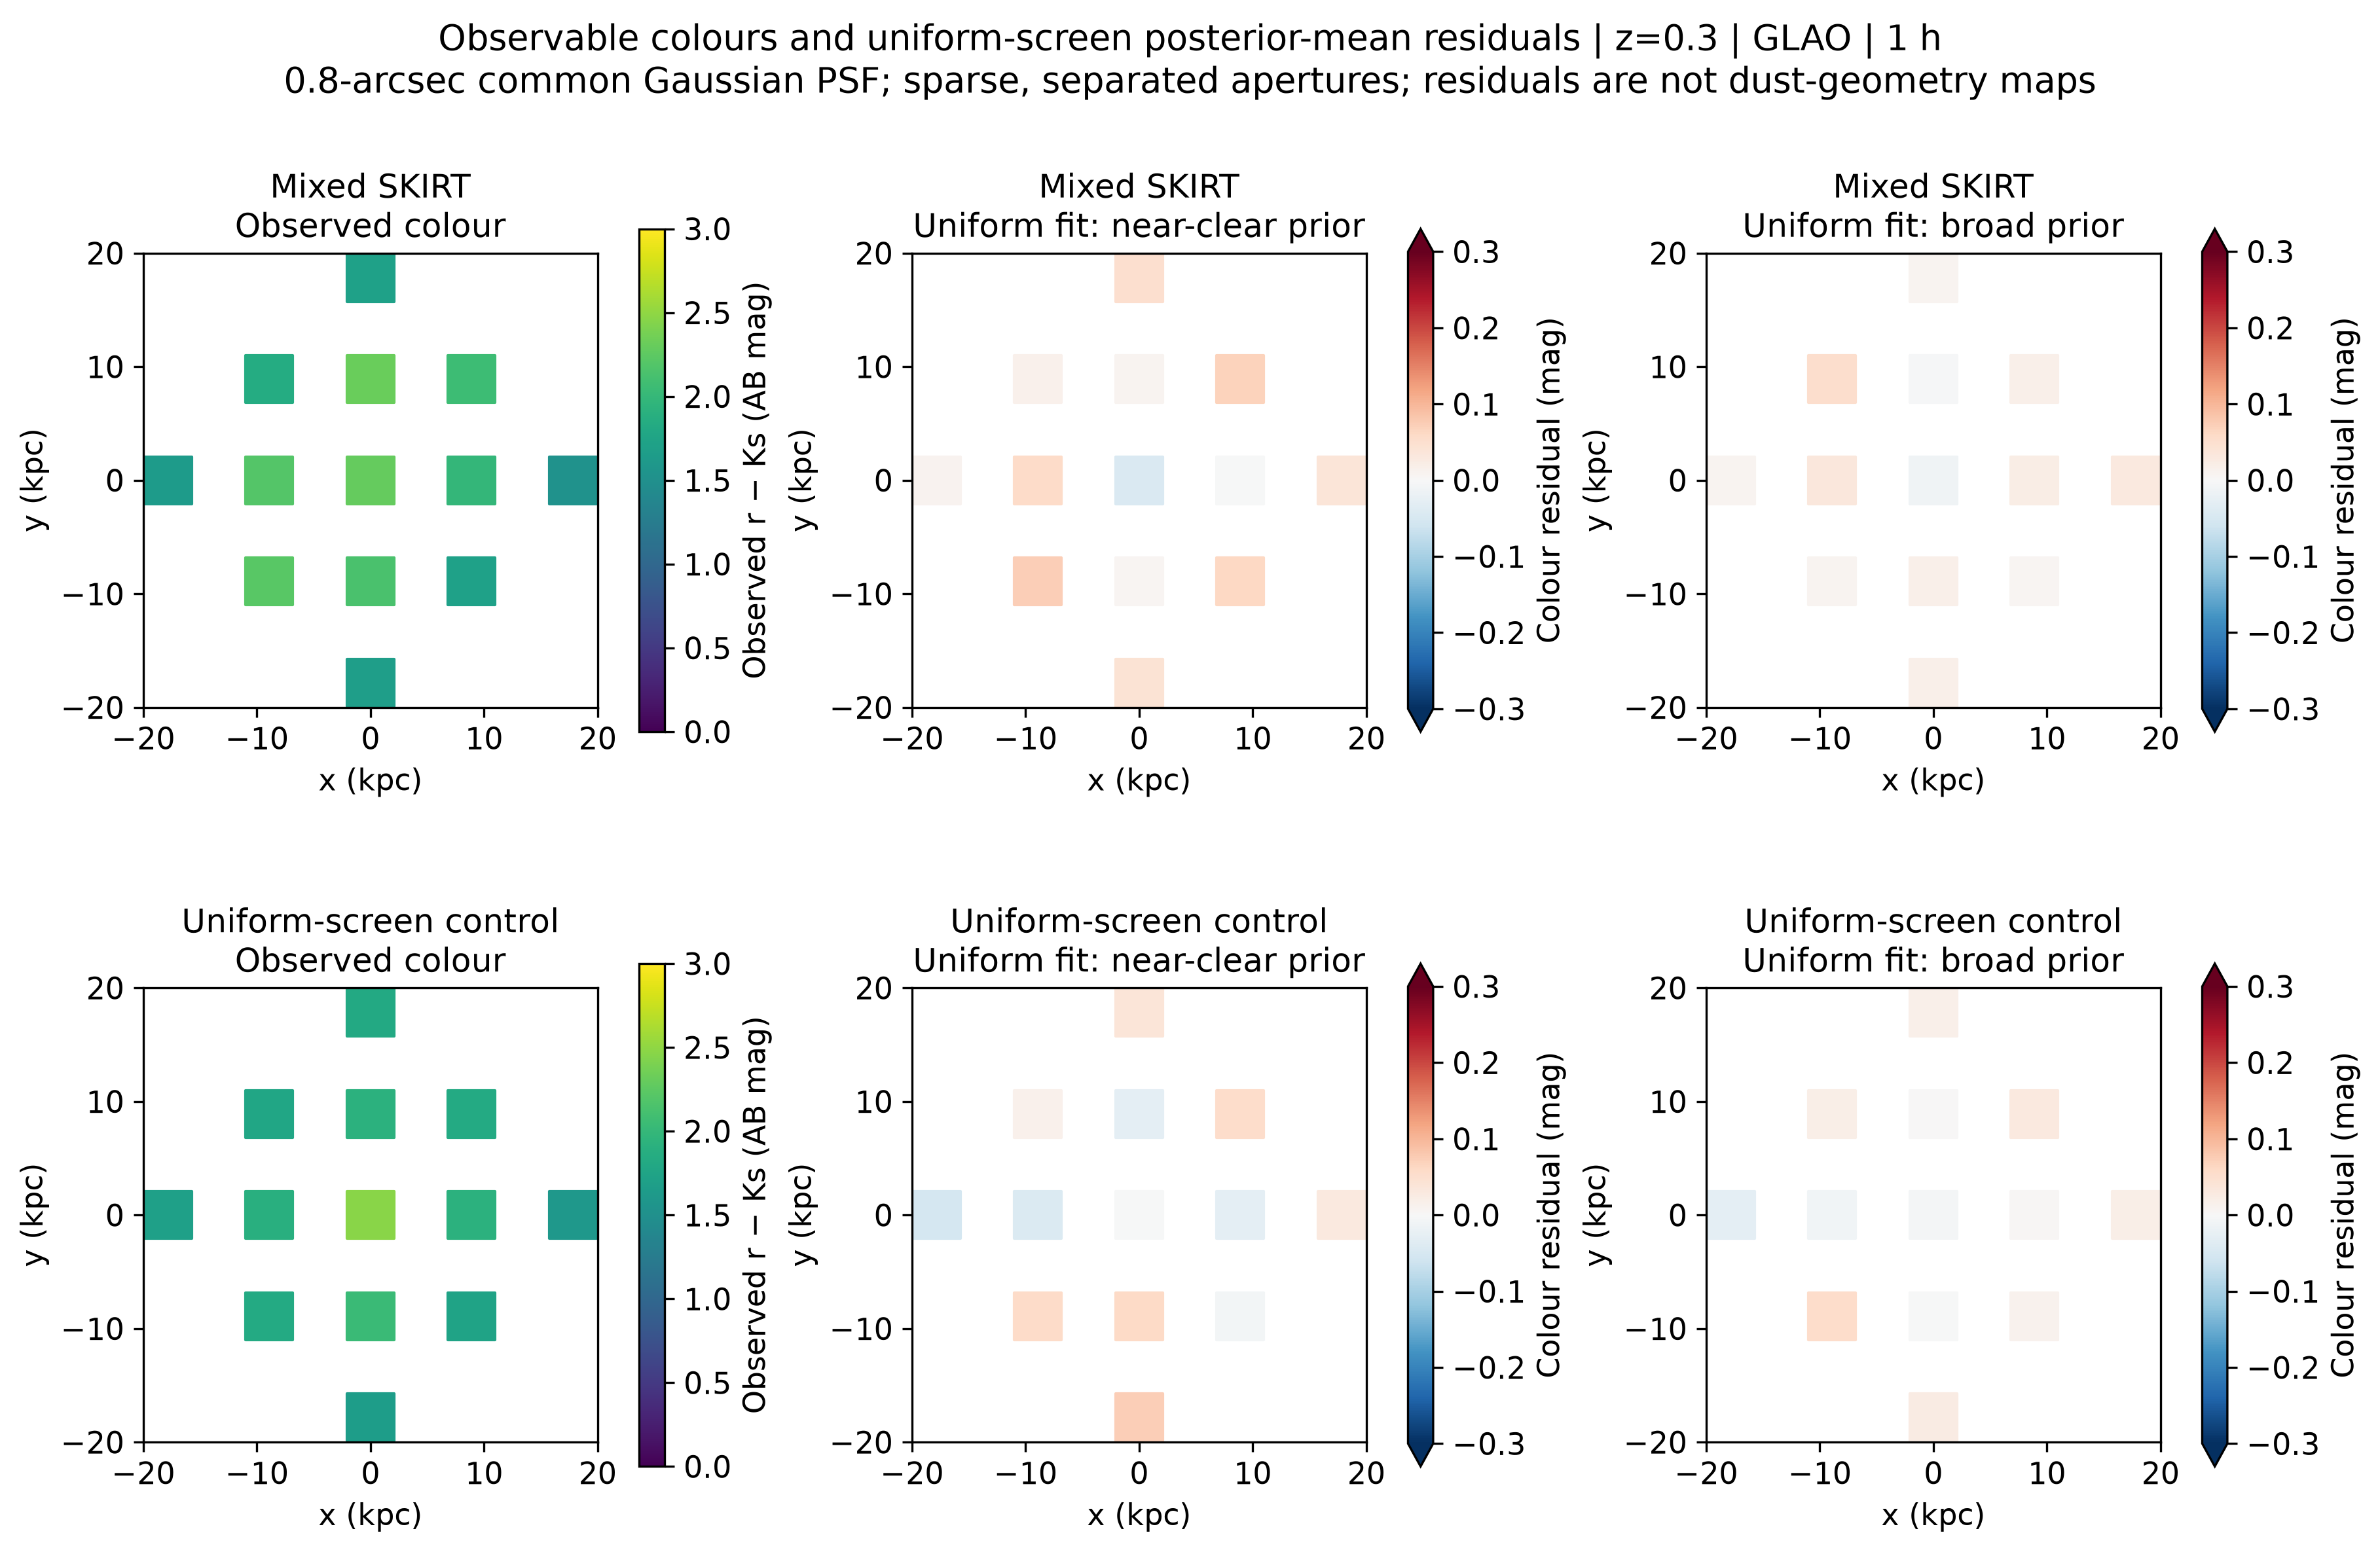

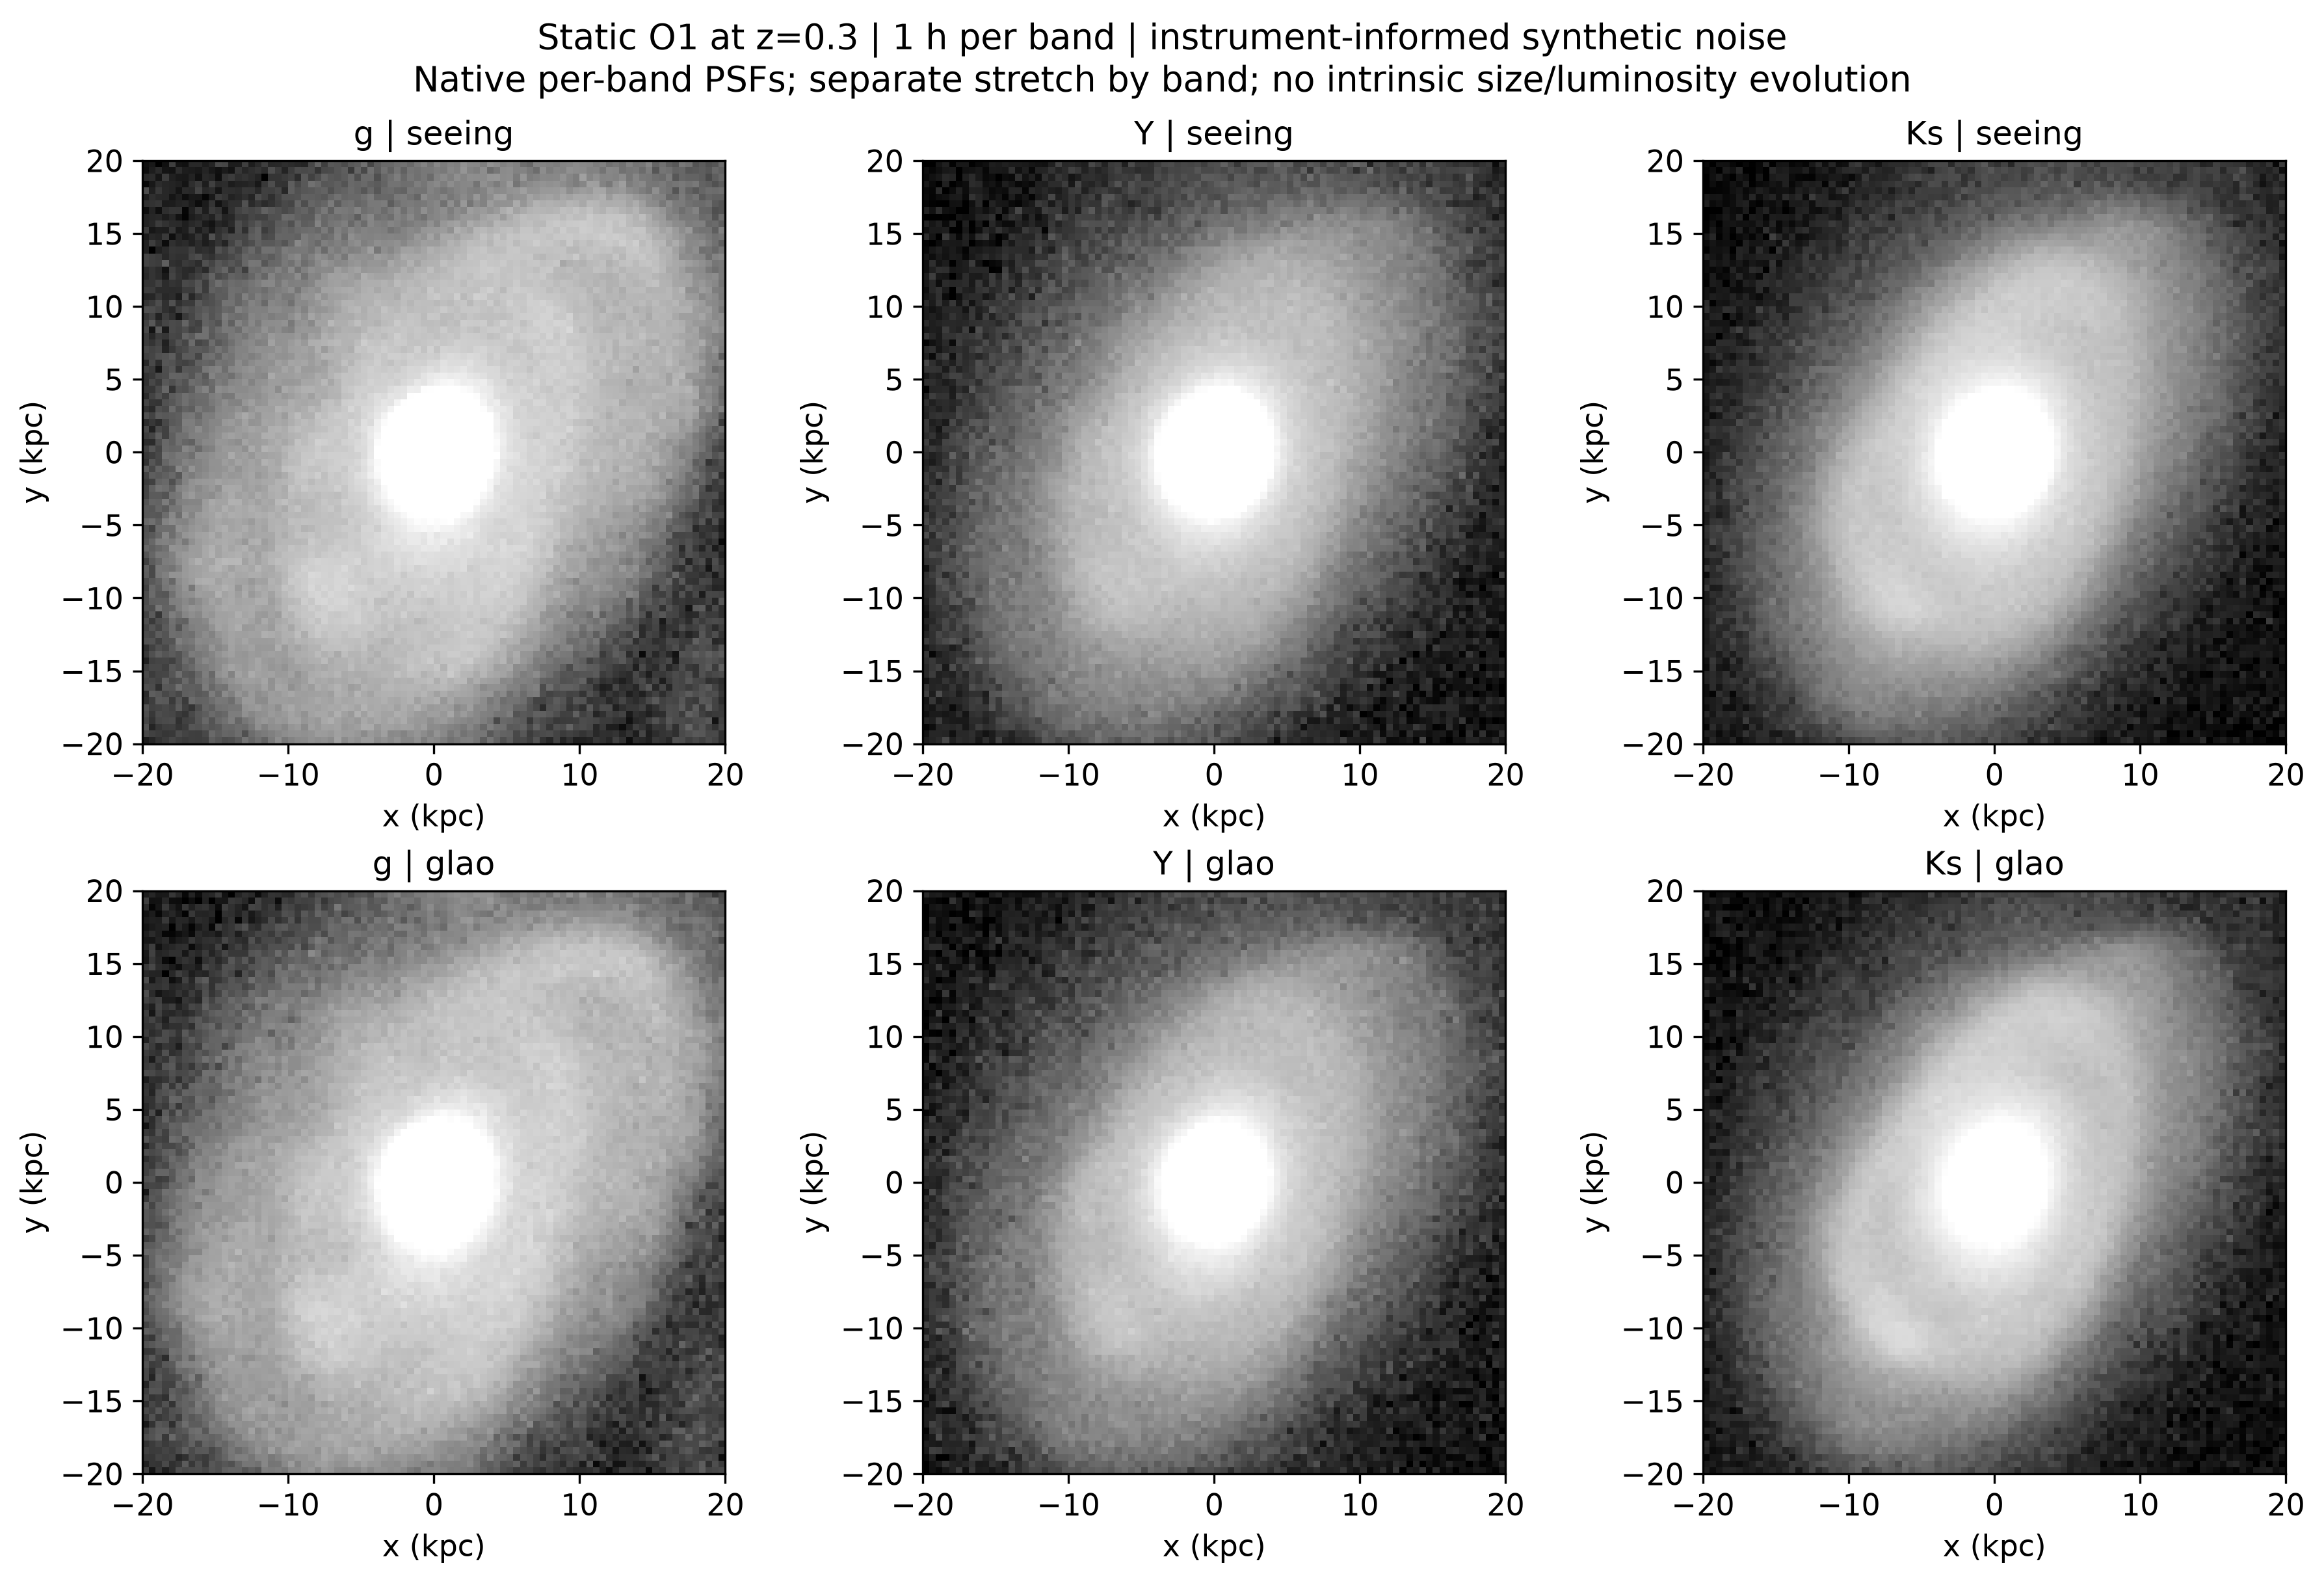

In [9]:
display(Image(filename=str(O/'figures/observable_colour_and_screen_residuals.png'),width=1100))
display(Image(filename=str(O/'figures/synthetic_observed_images.png'),width=1100))

### Conditional GLAO sensitivity gain
The native-NIR separation bound assumes the structured stellar scene is known and compares mixed SKIRT against the matched-integrated-g uniform control. Optimizing one amplitude per band removes global colour/flux offsets, but it does not marginalize unknown spatial populations or 3D dust alternatives. Full observational screen rejection does not show a robust GLAO gain under these assumptions.

,z,glao,optimistic,seeing,GLAO_gain_percent
0,0.1,1125.7113,1202.0871,1099.5904,2.3755
1,0.3,277.0875,311.0500,262.5546,5.5352
2,0.6,96.8227,114.7458,88.6930,9.1661
3,1.0,39.6981,48.8343,35.2964,12.4708


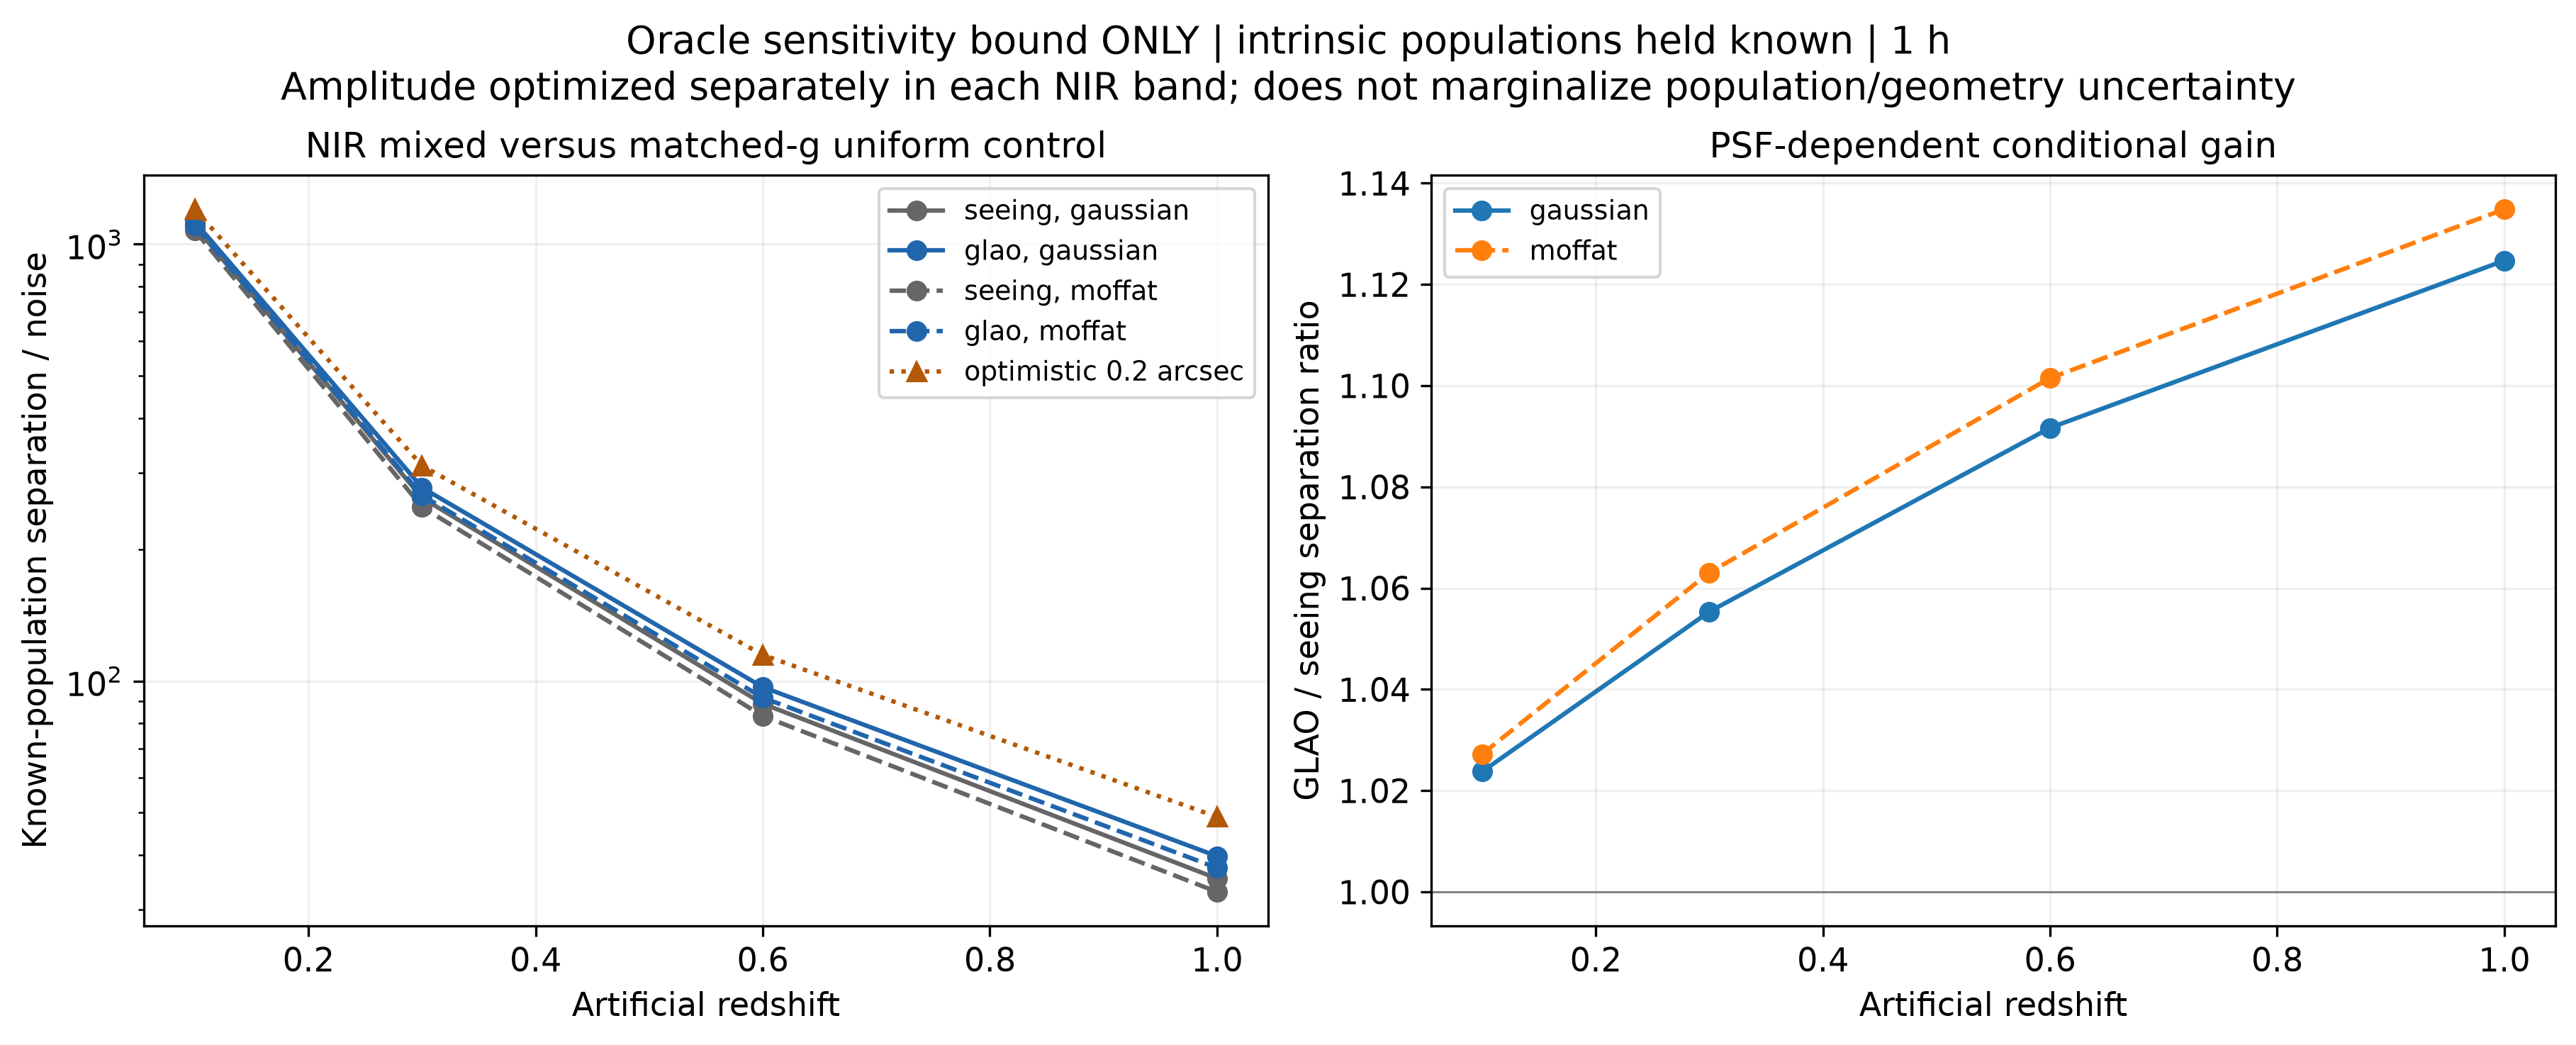

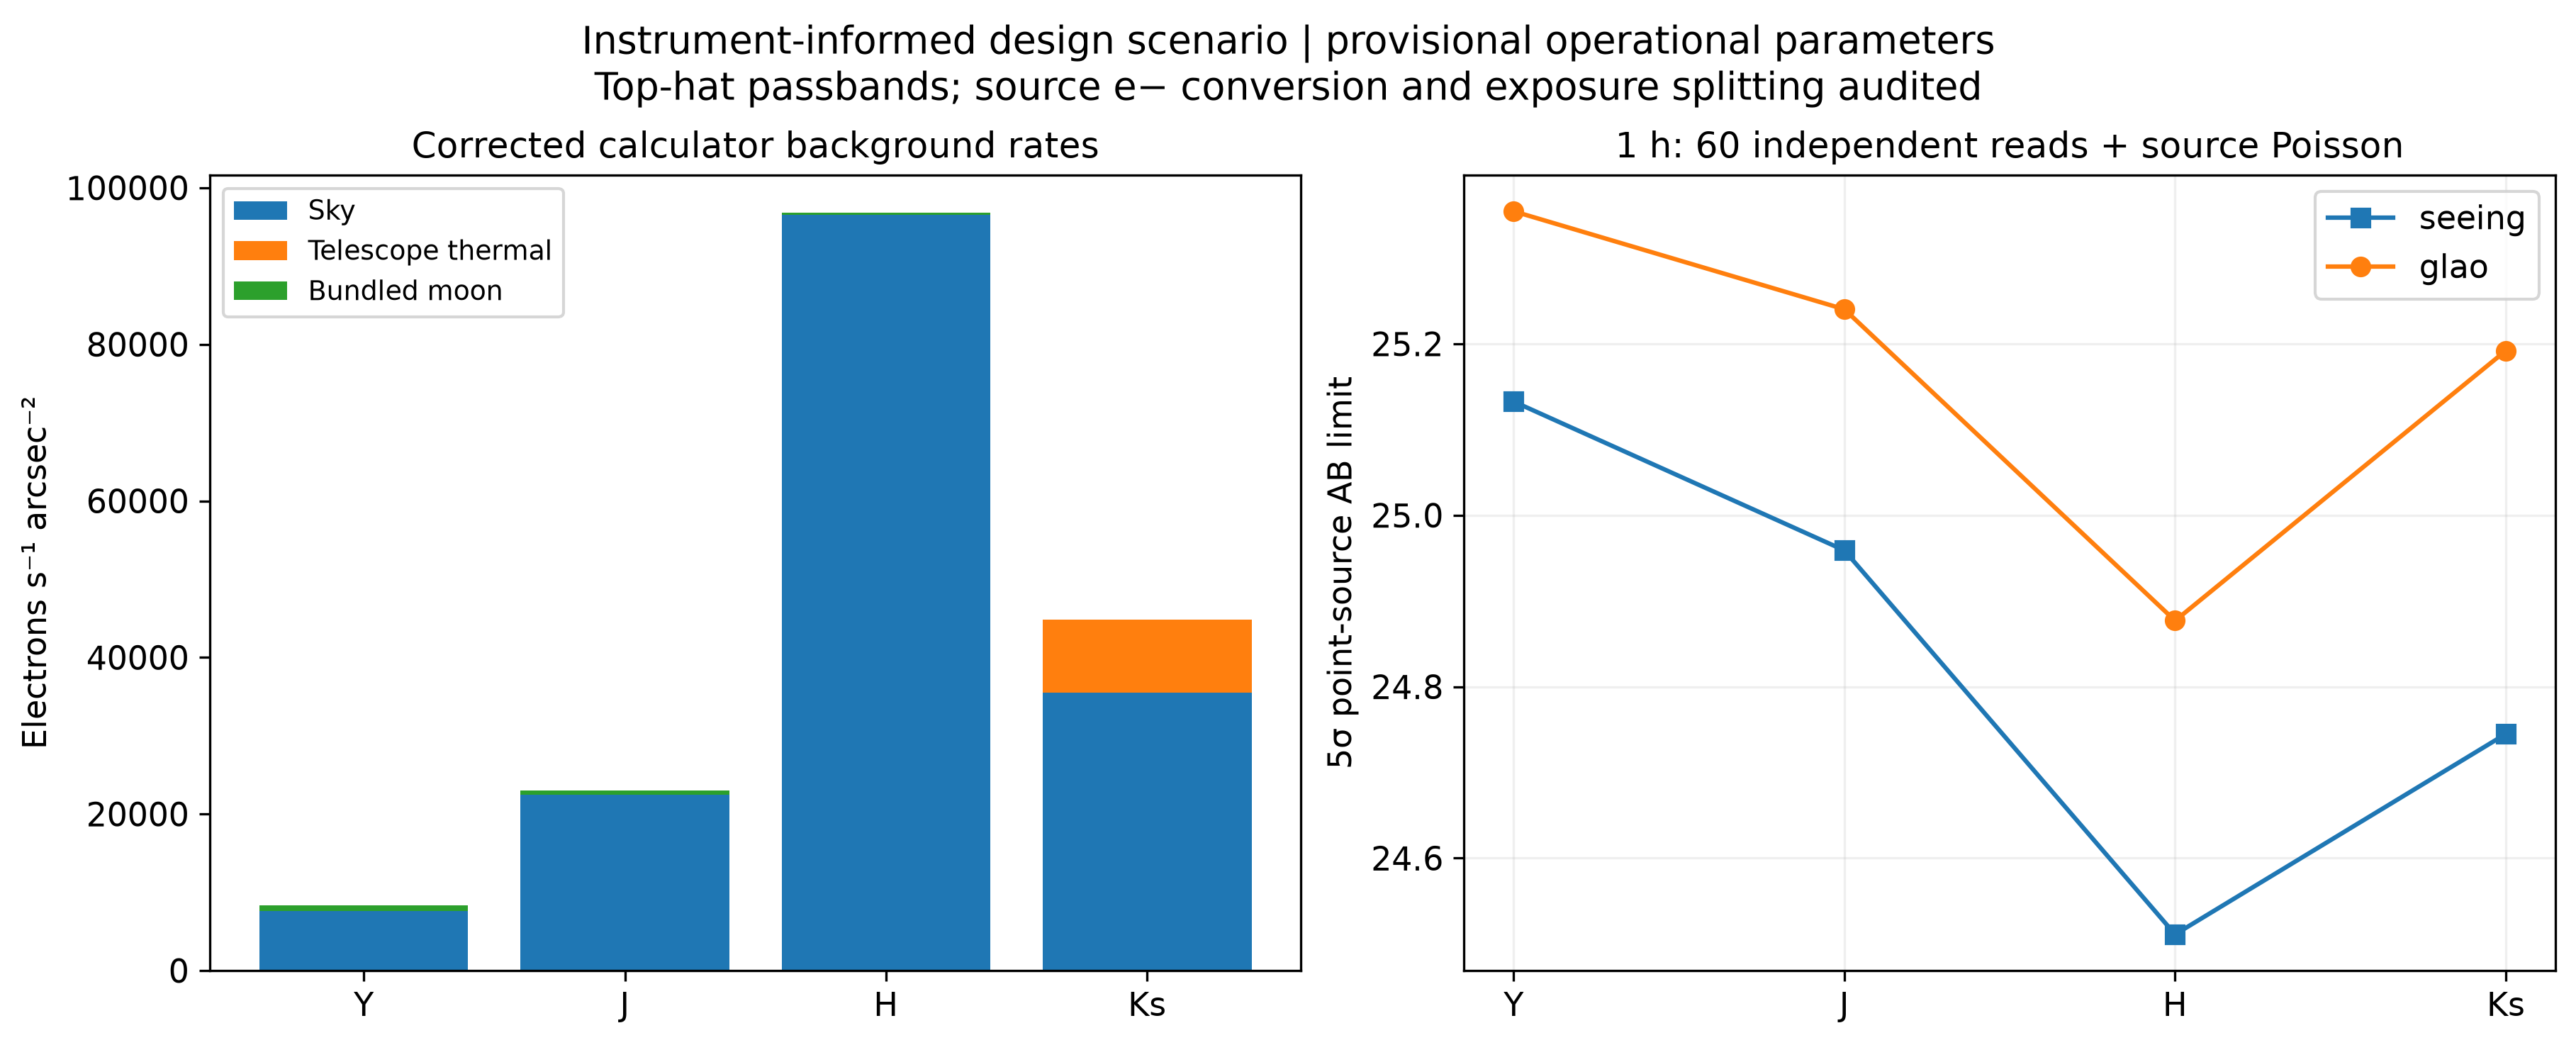

In [10]:
display(pd.read_csv(O/'glao_oracle_gain.csv').round(4))
display(Image(filename=str(O/'figures/glao_oracle_upper_bound.png'),width=1200))
display(Image(filename=str(O/'figures/instrument_noise_audit.png'),width=1100))

### Final numerical checks
Flux conservation includes PSF padding and exact area-overlap detector integration. Aperture errors propagate convolution weights squared. See `review_notes.md` for the independent scientific review and Av-grid convergence check. The main physical null failure persists under grid refinement; it is not cured by optimizer convergence or finer dust bins.

In [11]:
transfer=pd.read_csv(O/'transfer_validation.csv')
assert len(transfer)==48
assert transfer.max_flux_relative_error.max()<1e-9
assert results.loc[results.status=='fit','max_adjacent_background_correlation'].max()<.001
assert results.loc[results.status=='fit','log_B_variable_uniform'].notna().all()
print('Maximum fractional full-field flux error:',transfer.max_flux_relative_error.max())
print('Maximum adjacent background correlation:',results.max_adjacent_background_correlation.max())
display(pd.read_csv(O/'spectral_interpolation_sensitivity.csv'))
print('All kernel cells executed; figure/table outputs retained.')

Maximum fractional full-field flux error: 1.0103029524088925e-13
Maximum adjacent background correlation: 7.84436414231943e-05


,orientation,z,mode,median_photometry_relative_change,max_photometry_relative_change
0,O1,0.3,seeing,0.013117,0.057169
1,O1,0.3,glao,0.011663,0.057169
2,O1,0.6,seeing,0.025032,0.107082
3,O1,0.6,glao,0.022085,0.107082


All kernel cells executed; figure/table outputs retained.


## Takeaways
1. The implemented static forward transfer is validated numerically and leaves the structured galaxy fixed.
2. Spatial colour variations survive, but even uniform-dust controls show them. Colours alone do not establish non-uniform attenuation.
3. Screen-model preferences depend on external population and SED-discrepancy assumptions. Physical uniform controls fail in some regimes. No robust uniform-screen rejection or unique mixed-geometry detection has been established.
4. GLAO improves an explicitly privileged NIR sensitivity bound by approximately 2–12% across O1's redshift grid for the calculator Gaussian scenario. That is a conditional upper bound, not observational recovery.
5. Exact DR2 download location remains unverified in the authenticated listings; no archive was guessed or downloaded. Next priorities are validated resolved spectral/filter synthesis, population-complete physical null controls, per-band PSF joint fitting, realistic sky/systematic covariance and then independent galaxies. No ML training was started.

The [scientific report](scientific_report.md), [instrument audit](instrument_audit.md), [catalogue status](catalogue_status.md), CSV files and PNG/PDF figures are the handoff. Settings and assumptions are in `parameter_provenance.json`.